In [3]:
!pip install keras-tuner -q
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import keras_tuner as kt
from sklearn.metrics import *
from google.colab import drive
drive.mount('/content/drive')
RUTA_PROYECTO = '/content/drive/MyDrive/Proyecto-neumonia' # Especificar la ruta de la carpeta de tu Drive donde debe estar previamente el notebook 01_eda_y_preprocesado.ipynb
os.chdir(RUTA_PROYECTO)
tf.keras.utils.set_random_seed(230406)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
#@title Carga de los subconjuntos de datos guardados en Drive
X_train = np.load('X_train.npy')
y_train = np.load('y_train.npy')
X_val = np.load('X_val.npy')
y_val = np.load('y_val.npy')
X_test = np.load('X_test.npy')
y_test = np.load('y_test.npy')

print("Dimensiones de los conjuntos de datos cargados:")
print(f'X_train: {X_train.shape}') # Cambiar por el conjunto de datos aumentado
print(f'y_train: {y_train.shape}') # Cambiar por el conjunto de etiquetas aumentado
print(f'X_val: {X_val.shape}')
print(f'y_val: {y_val.shape}')
print(f'X_test: {X_test.shape}')
print(f'y_test: {y_test.shape}')

Dimensiones de los conjuntos de datos cargados:
X_train: (6823, 180, 180, 1)
y_train: (6823,)
X_val: (1575, 180, 180, 1)
y_val: (1575,)
X_test: (2100, 180, 180, 1)
y_test: (2100,)


In [15]:
#@title Definición del espacio de búsqueda para KerasTuner
# Esta función tiene como objetivo probar distintas arquitecturas, regularizaciones y entrenamientos según los hiperparámetros dados y obtener la mejor combinación
def build_model(hp):
  model = keras.Sequential()
  model.add(layers.Input(shape=(180,180,1)))
  l2_reg = hp.Choice('l2_rate', values=[0.0, 1e-4, 1e-3])

  # PARA LOS SIGUIENTES BLOQUES, CAMBIAR POR LA ARQUITECTURA BASE DE LA CNN DEL NOTEBOOK 2 PERO SIN CAMBIAR LOS HIPERPARÁMETROS DE REGULARIZACIÓN
  # Bloque 1 convolucional
  model.add(layers.Conv2D(
      filters = hp.Int('conv_1_filters', min_value=32, max_value=64, step=32),
      kernel_size = (3,3),
      padding='same',
      kernel_regularizer = regularizers.l2(l2_reg) if l2_reg > 0 else None
  ))
  if hp.Boolean('use_batchnorm'):
    model.add(layers.BatchNormalization())
  model.add(layers.Activation('relu'))
  model.add(layers.MaxPooling2D(pool_size=(2,2)))

  # Bloque 2 convolucional
  model.add(layers.Conv2D(
      filters = hp.Int('conv_2_filters', min_value=64, max_value=128, step=64),
      kernel_size = (3,3),
      padding='same',
      kernel_regularizer = regularizers.l2(l2_reg) if l2_reg > 0 else None
  ))
  if hp.Boolean('use_batchnorm'):
    model.add(layers.BatchNormalization())
  model.add(layers.Activation('relu'))
  model.add(layers.MaxPooling2D(pool_size=(2,2)))

  # Bloque denso
  model.add(layers.Flatten())
  model.add(layers.Dense(
      units = hp.Int('dense_units', min_value=64, max_value=256, step=64),
      kernel_regularizer = regularizers.l2(l2_reg) if l2_reg > 0 else None
  ))
  if hp.Boolean('use_batchnorm'):
    model.add(layers.BatchNormalization())
  model.add(layers.Activation('relu'))

  # Dropout
  dropout_rate = hp.Float('dropout_rate', min_value=0.2, max_value=0.5, step=0.1)
  model.add(layers.Dropout(dropout_rate))

  # Capa de salida
  model.add(layers.Dense(1, activation='sigmoid'))

  # Hiperparámetros del optimizador
  lr = hp.Choice('learning_rate', values=[1e-3, 5e-4, 1e-4])
  optimizer_choice = hp.Choice('optimizer', values=['adam', 'rmsprop'])

  optimizer = keras.optimizers.Adam(learning_rate=lr) if optimizer_choice == 'adam' else keras.optimizers.RMSprop(learning_rate=lr)

  model.compile(
      optimizer=optimizer,
      loss='binary_crossentropy',
      metrics=['accuracy', tf.keras.metrics.Recall(name='recall'), tf.keras.metrics.AUC(name='auc')]
  )

  return model

In [17]:
#@title Configuración de callbacks y Tuner

early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6)

tuner = kt.RandomSearch(
    build_model,
    objective=kt.Objective('val_auc', direction='max'),
    max_trials=8,
    executions_per_trial=1,
    directory='tuner_results',
    project_name='tuner_neumonia',
    overwrite=True
)

tuner.search_space_summary()

Search space summary
Default search space size: 8
l2_rate (Choice)
{'default': 0.0, 'conditions': [], 'values': [0.0, 0.0001, 0.001], 'ordered': True}
conv_1_filters (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 64, 'step': 32, 'sampling': 'linear'}
use_batchnorm (Boolean)
{'default': False, 'conditions': []}
conv_2_filters (Int)
{'default': None, 'conditions': [], 'min_value': 64, 'max_value': 128, 'step': 64, 'sampling': 'linear'}
dense_units (Int)
{'default': None, 'conditions': [], 'min_value': 64, 'max_value': 256, 'step': 64, 'sampling': 'linear'}
dropout_rate (Float)
{'default': 0.2, 'conditions': [], 'min_value': 0.2, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.01, 0.0001], 'ordered': True}
optimizer (Choice)
{'default': 'adam', 'conditions': [], 'values': ['adam', 'rmsprop'], 'ordered': False}


In [18]:
#@title Búsqueda automática de hiperparámetros

tuner.search(
    X_train, y_train, # Cambiar por los conjuntos de datos aumentados
    epochs=12,
    batch_size=32,
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr]
)

tuner.results_summary(num_trials=3)

Trial 8 Complete [00h 03m 37s]
val_recall: 0.9517766237258911

Best val_recall So Far: 1.0
Total elapsed time: 00h 22m 48s
Results summary
Results in Proyecto-neumonia/tuner_neumonia
Showing 3 best trials
Objective(name="val_recall", direction="max")

Trial 0 summary
Hyperparameters:
l2_rate: 0.001
conv_1_filters: 32
use_batchnorm: False
conv_2_filters: 128
dense_units: 256
dropout_rate: 0.4
learning_rate: 0.01
optimizer: adam
Score: 1.0

Trial 1 summary
Hyperparameters:
l2_rate: 0.001
conv_1_filters: 64
use_batchnorm: True
conv_2_filters: 64
dense_units: 192
dropout_rate: 0.4
learning_rate: 0.01
optimizer: adam
Score: 1.0

Trial 2 summary
Hyperparameters:
l2_rate: 0.0001
conv_1_filters: 32
use_batchnorm: True
conv_2_filters: 128
dense_units: 128
dropout_rate: 0.30000000000000004
learning_rate: 0.01
optimizer: rmsprop
Score: 1.0


In [19]:
#@title Re-entrenamiento y guardado del mejor modelo en Drive

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
best_model = tuner.hypermodel.build(best_hps)

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    'best_model_notebook04.keras',
    save_best_only=True,
    monitor='val_loss'
)

history = best_model.fit(
    X_train, y_train, # Cambiar por los conjuntos de datos aumentados
    epochs=20,   # Poner las mismas épocas (o incluso 5 o 10 más) que las utilizadas en el notebook 2
    batch_size=32, # Cambiar por el tamaño de batch utilizado en el notebook 2
    validation_data=(X_val, y_val),
    callbacks=[early_stopping, reduce_lr, checkpoint_cb]
)

Epoch 1/20
214/214 ━━━━━━━━━━━━━━━━━━━━ 25s 102ms/step - accuracy: 0.4977 - loss: 7.6752 - recall: 0.7649 - val_accuracy: 0.5003 - val_loss: 0.7825 - val_recall: 1.0000 - learning_rate: 0.0100
Epoch 2/20
214/214 ━━━━━━━━━━━━━━━━━━━━ 23s 109ms/step - accuracy: 0.4963 - loss: 0.7386 - recall: 0.4072 - val_accuracy: 0.5003 - val_loss: 0.7277 - val_recall: 1.0000 - learning_rate: 0.0100
Epoch 3/20
214/214 ━━━━━━━━━━━━━━━━━━━━ 24s 110ms/step - accuracy: 0.4944 - loss: 0.7257 - recall: 0.4269 - val_accuracy: 0.5003 - val_loss: 0.7237 - val_recall: 1.0000 - learning_rate: 0.0100
Epoch 4/20
214/214 ━━━━━━━━━━━━━━━━━━━━ 27s 124ms/step - accuracy: 0.4964 - loss: 0.7225 - recall: 0.4055 - val_accuracy: 0.5003 - val_loss: 0.7211 - val_recall: 1.0000 - learning_rate: 0.0100
Epoch 5/20
214/214 ━━━━━━━━━━━━━━━━━━━━ 26s 120ms/step - accuracy: 0.4964 - loss: 0.7206 - recall: 0.4055 - val_accuracy: 0.5003 - val_loss: 0.7196 - val_recall: 1.0000 - learning_rate: 0.0100
Epoch 6/20
214/214 ━━━━━━━━━━━━━━━━

66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 43ms/step


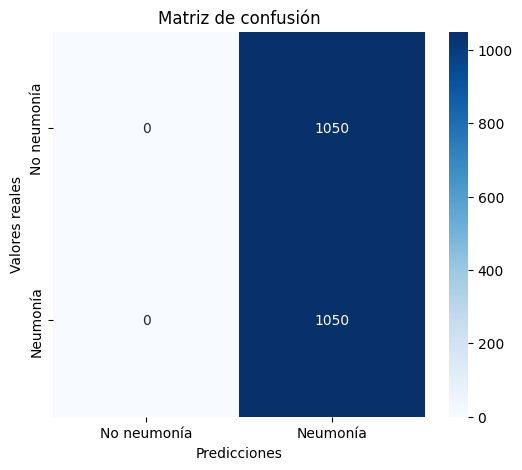

Clasificación:
              precision    recall  f1-score   support

 No Neumonía       0.00      0.00      0.00      1050
    Neumonía       0.50      1.00      0.67      1050

    accuracy                           0.50      2100
   macro avg       0.25      0.50      0.33      2100
weighted avg       0.25      0.50      0.33      2100



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [21]:
#@title Evaluación y gráfica de matriz de confusión sobre X_test

# PARA ESTA CELDA DEBO FIJARME EN LAS MÉTRICAS Y SU PROCEDIMIENTO REALIZADO EN EL NOTEBOOK 2
final_model = keras.models.load_model('best_model_notebook04.keras')

y_pred_prob = final_model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No neumonía', 'Neumonía'], yticklabels=['No neumonía', 'Neumonía'])
plt.xlabel('Predicciones')
plt.ylabel('Valores reales')
plt.title('Matriz de confusión')
plt.show()

print('Clasificación:')
print(classification_report(y_test, y_pred, target_names=['No Neumonía', 'Neumonía']))